#Deterministic vs Stochastic(Probabilistic) Policy

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Gridworld:
    def __init__(self, size):
        self.size = size
        self.start_state = (0,0)
        self.goal_state = (size-1, size-1)
        self.current_state = self.start_state

    def reset(self):
        self.current_state = self.start_state
        return self.current_state

    def step(self, action):
        row, col = self.current_state

        if action == 0: #Right
            col = min(col + 1, self.size - 1)
        elif action == 1: #Up
            row = max(row - 1, 0)
        elif action == 2: #Left
            col = max(col - 1, 0)
        else: #Down
            row = min(row + 1, self.size - 1)

        self.current_state = (row, col)

        if self.current_state == self.goal_state:
            self.reset()
            return 1, self.current_state
        return 0, self.current_state

#stochastic (epsilon-greedy) policy

In [3]:
def epsilon_greedy(Q, epsilon):
    if np.random.uniform() < epsilon:
        return np.random.randint(len(Q))
    return np.argmax(Q)

#deterministic (greedy) policy

In [4]:
def greedy(Q):
    return np.argmax(Q)

#parameters

In [5]:
size = 4
n_steps = 100
n_trials = 100
epsilons = [0.1, 0.3, 0.5]

stochastic_policy_rewards = np.zeros((len(epsilons), n_steps))
deterministic_policy_rewards = np.zeros((len(epsilons), n_steps))

#policy iteration for both methods

In [6]:
for i, epsilon in enumerate(epsilons):

    #1. stochastic trials
    Q_stoch = np.zeros((size, size, 4))
    for j in range(n_trials):
        gridworld = Gridworld(size)
        total_reward = 0
        rewards = np.zeros(n_steps)

        for step in range(n_steps):
            state = gridworld.current_state
            action = epsilon_greedy(Q_stoch[state], epsilon)
            reward, next_state = gridworld.step(action)
            total_reward += reward
            rewards[step] = total_reward
            Q_stoch[state][action] += (reward - Q_stoch[state][action]) / (j+1)

        stochastic_policy_rewards[i] += rewards/n_trials

    #2. deterministic trials
    Q_det = np.zeros((size, size, 4))
    for j in range(n_trials):
        gridworld = Gridworld(size)
        total_reward = 0
        rewards = np.zeros(n_steps)

        for step in range(n_steps):
            state = gridworld.current_state
            action = greedy(Q_det[state])
            reward, next_state = gridworld.step(action)
            total_reward += reward
            rewards[step] = total_reward
            Q_det[state][action] += (reward - Q_det[state][action]) / (j+1)
    
        deterministic_policy_rewards[i] = rewards/n_trials

#visualization

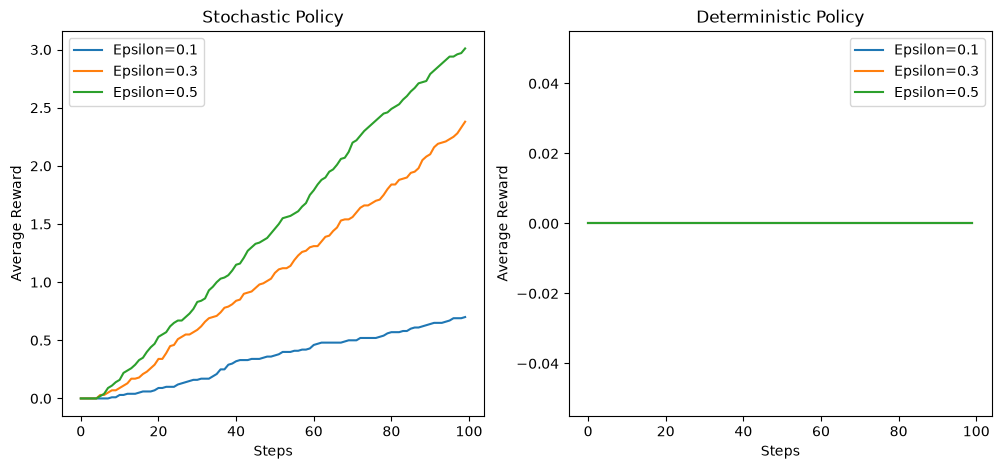

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

for i, epsilon in enumerate(epsilons):
    axs[0].plot(stochastic_policy_rewards[i], label="Epsilon={}".format(epsilon))
    axs[1].plot(deterministic_policy_rewards[i], label="Epsilon={}".format(epsilon))

axs[0].set_title('Stochastic Policy')
axs[0].set_xlabel('Steps')
axs[0].set_ylabel('Average Reward')
axs[0].legend()

axs[1].set_title('Deterministic Policy')
axs[1].set_xlabel('Steps')
axs[1].set_ylabel('Average Reward')
axs[1].legend()

plt.show()